# A Transformer-Based Approach for Raw EEG Classification

### 1. Setup and Imports

Import necessary libraries and set up the environment.



In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [3]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))
from datapreprocessing import EEGpreprocessing, EEGDataset
from train import EarlyStopper, EEGTrainer
from rozzotrain import EarlyStopper, EEGTrainer

#from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, ConvolutionModule, EEGConformer, EEGTransformerConv1D
from models import ScaledDotProductAttention, MultiHeadAttention, FeedForward, TransformerLayer, SpatialCNN, TemporalCNN, PositionalEncoding,  F_CTrans


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Configuration and Hyperparameters

Define all model and training parameters

### 3. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [4]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorMovement(03,07,011)") if CURRENT_DIR.name == "notebook" else (CURRENT_DIR / "data" / "MotorMovement(03,07,011)")

print(f"Percorso dataset utilizzato: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

# Split riproducibile sui SOGGETTI (Test set isolato)
np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")

Percorso dataset utilizzato: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorMovement(03,07,011)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  # 📊 Lista per salvare i valori numerici della PSD

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    # 1. CALCOLO CORRETTO DELLA PSD (Metodo moderno di MNE)
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch')
    
    # 2. ESTRAZIONE DEI VALORI NUMERICI DELLA PSD
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    # Shape di psd_values: (n_epochs, n_channels, n_freqs)
    
    # Salviamo i valori numerici associati al soggetto
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,                # Vettore delle frequenze (es. 1 Hz, 2 Hz, ...)
        'psd_data': psd_values,              # Valori di potenza spettrale
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2)) # Potenza media per canale
    })


    if len(epochs_mne) == 0:
        continue
    
    # Estraiamo i dati grezzi delle epoche
    X_raw = epochs_mne.get_data(copy=True) 

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    labels = np.zeros(len(y), dtype=np.int64)
    labels[y == event_id['Left']] = 0
    labels[y == event_id['Right']] = 1

    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

/tmp/ipykernel_56895/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
/tmp/ipykernel_56895/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)


/tmp/ipykernel_56895/785558903.py:14: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Effective window size : 4.006 (s)
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 project

In [6]:
'''
for i, record in enumerate(psd_records[:4]):
    print(f"--- Paziente {i+1} ---")
    print(f"Subject ID: {record['subject_id']}")
    print(f"Shape della PSD (epoche, canali, frequenze): {record['psd_data'].shape}")
    print(f"Potenza media per canale (primi 5 canali): {record['mean_power_per_channel'][:63]}")
    print("-" * 30)
'''

'\nfor i, record in enumerate(psd_records[:4]):\n    print(f"--- Paziente {i+1} ---")\n    print(f"Subject ID: {record[\'subject_id\']}")\n    print(f"Shape della PSD (epoche, canali, frequenze): {record[\'psd_data\'].shape}")\n    print(f"Potenza media per canale (primi 5 canali): {record[\'mean_power_per_channel\'][:63]}")\n    print("-" * 30)\n'

Convert to PyTorch tensors

In [6]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Dimensioni X_train_val grezzo: {X_training_validation_raw.shape}")
print(f"Dimensioni y_train_val: {y_training_validation.shape}")
print("Distribuzione etichette:", np.unique(y_training_validation, return_counts=True))

Dimensioni X_train_val grezzo: (4402, 64, 641)
Dimensioni y_train_val: (4402,)
Distribuzione etichette: (array([0, 1]), array([2203, 2199]))


In [7]:
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)


In [8]:
#Sto facewndo il coice full che con i dati immaginari funziona

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")



# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 64        # Ridotto a 32 per stabilizzare i gradienti sui Transformer EEG
EPOCHS = 50            # Leggermente aumentate, ci pensa l'Early Stopping a fermare tutto
LR = 0.001        # Learning rate leggermente più prudente per il Transformer
WEIGHT_DECAY = 0.1   # Strong weight decay per regolarizzare contro l'overfitting
ALPHA_NOISE = 0.01     # Intensità del rumore di augmentation
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = F_CTrans(num_channels = 64 ,d_model= 64, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
   
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
  
    # H. Trainer personalizzato
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    print("Controllo rapido del batch di training...")
    for inputs, labels in train_loader:
        print(f"Forma batch input: {inputs.shape} (Atteso: [Batch, 64, 641])")
        print(f"Forma batch labels: {labels.shape} (Atteso: [Batch])")
        print(f"Tipo dati labels: {labels.dtype} (Atteso: torch.int64)")
        
        # Test di forward pass per verificare che non ci siano crash di shape
        outputs, _ = model(inputs.to(device))
        print(f"Forma output modello: {outputs.shape} (Atteso: [Batch, 2])")
        break
    print("Diagnostica superata con successo! Avvio le epoche...\n")

    # I. Training e Validazione con Early Stopping integrato
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS
    )

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    # Salvataggio del modello migliore assoluto
    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
print(f"\n🎉 TRAINING COMPLETATO SU TUTTI I FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 641]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/50: train_loss=0.74071, val_loss=0.70064, val_acc=50.17%
Epoch 02/50: train_loss=0.69537, val_loss=0.70633, val_acc=49.83%
Epoch 03/50: train_loss=0.70010, val_loss=0.70855, val_acc=50.17%
Epoch 04/50: train_loss=0.69803, val_loss=0.69346, val_acc=49.83%
Epoch 05/50: train_loss=0.70042, val_loss=0.69319, val_acc=50.17%
Epoch 06/50: train_loss=0.69530, val_loss=0.69513, val_acc=49.83%
Epoch 07/50: train_loss=0.69481, val_loss=0.69452, val_acc=49.83%
Epoch 08/50: train_loss=0.69456, val_loss=0.69682, val_acc=50.17%
Epoch 09/50: train_loss=0.70016, val_loss=0.70336, val_acc=50.17%
Epoch 10/50: train_loss=0.69466, val_loss=0.69870, val_acc=49.83%
Epoch 11/50: train_loss=0.69383, val_loss=0.70330, val_acc=49.83%
Epoch 12/50: train_loss=0.69443, val_loss=0.69230, val_acc=52.50%
Epoch 13/50: train_loss=0.69384, val_loss=0.69258, val_acc=49.83%
Epoch 14/50: train_loss=

KeyboardInterrupt: 

### Cross-Individual 3-Fold Cross-Validation and Random grid search to tuning hyperparameters

## Gfk 

In [9]:

# ==========================================
# 3. CICLO DI CROSS-VALIDATION COMPLETO (5 FOLD - GROUP K-FOLD)
# ==========================================
EPOCHS = 30
all_fold_best_accs = []
all_fold_best_losses = []

print("==========================================")
print("🚀 INIZIO CROSS-VALIDATION 5-FOLD COMPLETA CON I PARAMETRI OTTIMALI")
print("==========================================")

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 (Cross-Subject) ---")

    # A. Divisione dei dati grezzi in base al fold del GroupKFold
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]

    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # F. Inizializzazione del Modello EEG Conformer con i parametri vincenti della Grid Search
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=32, 
        nhead=4, num_layers=1, d_ff=128, 
        dropout=best_hyperparams['dropout'], num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler configurati con i iperparametri ottimali
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(), lr=best_hyperparams['lr'], weight_decay=best_hyperparams['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # H. Inizializzazione della classe EEGTrainer
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )
    trainer.scheduler = scheduler

    # I. Avvio dell'addestramento tramite il metodo della classe
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    max_fold_acc = max(val_accuracies)
    min_fold_loss = min(val_losses)
    
    all_fold_best_accs.append(max_fold_acc)
    all_fold_best_losses.append(min_fold_loss)

    print(f"✅ Fold {fold + 1} completato | Min Val Loss: {min_fold_loss:.4f} | Max Val Acc: {max_fold_acc*100:.2f}%")

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY PER IL FOLD
    # ==========================================
    plt.figure(figsize=(14, 5))

    # Pannello 1: Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Andamento della Loss - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss (CrossEntropy + Label Smoothing)')
    plt.legend()
    plt.grid(True, linestyle=':')

    # Pannello 2:
    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Andamento Validation Accuracy - Cross-Subject Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()

# ==========================================
# 4. RISULTATO FINALE COMPLESSIVO
# ==========================================
print(f"\n==========================================")
print(f"🎯 RISULTATO FINALE CROSS-SUBJECT (GROUP K-FOLD)")
print(f"==========================================")
print(f"Accuracy media sui 5 fold: {np.mean(all_fold_best_accs) * 100:.2f}% (± {np.std(all_fold_best_accs) * 100:.2f}%)")
print(f"Validation Loss media (minima): {np.mean(all_fold_best_losses):.4f}")

🚀 INIZIO CROSS-VALIDATION 5-FOLD COMPLETA CON I PARAMETRI OTTIMALI

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 (Cross-Subject) ---


KeyboardInterrupt: 

CODICE NUOVO

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
--- Diagnostica Normalizzazione Training Set ---
Minimo: -11.5112
Massimo: 10.2882
Media globale: -0.0000
Deviazione standard globale: 1.0000
Presenza di NaN? ✅ No
Presenza di Inf? ✅ No
---------------------------------------------
Controllo rapido del batch di training...
Forma batch input: torch.Size([64, 64, 641]) (Atteso: [Batch, 64, 641])
Forma batch labels: torch.Size([64]) (Atteso: [Batch])
Tipo dati labels: torch.int64 (Atteso: torch.int64)
Forma output modello: torch.Size([64, 2]) (Atteso: [Batch, 2])
Diagnostica superata con successo! Avvio le epoche...

Epoch 01/20: train_loss=0.69706, val_loss=0.69366, val_acc=49.83%
Epoch 02/20: train_loss=0.69564, val_loss=0.69296, val_acc=49.71%
Epoch 03/20: train_loss=0.69440, val_loss=0.69325, val_acc=49.83%
Epoch 04/20: train_loss=0.69275, val_loss=0.69247, val_acc=51.92%
Epoch 05/20: train_loss=0.68845, val_loss=0.75777, val_acc=49.83%
Epoch 0

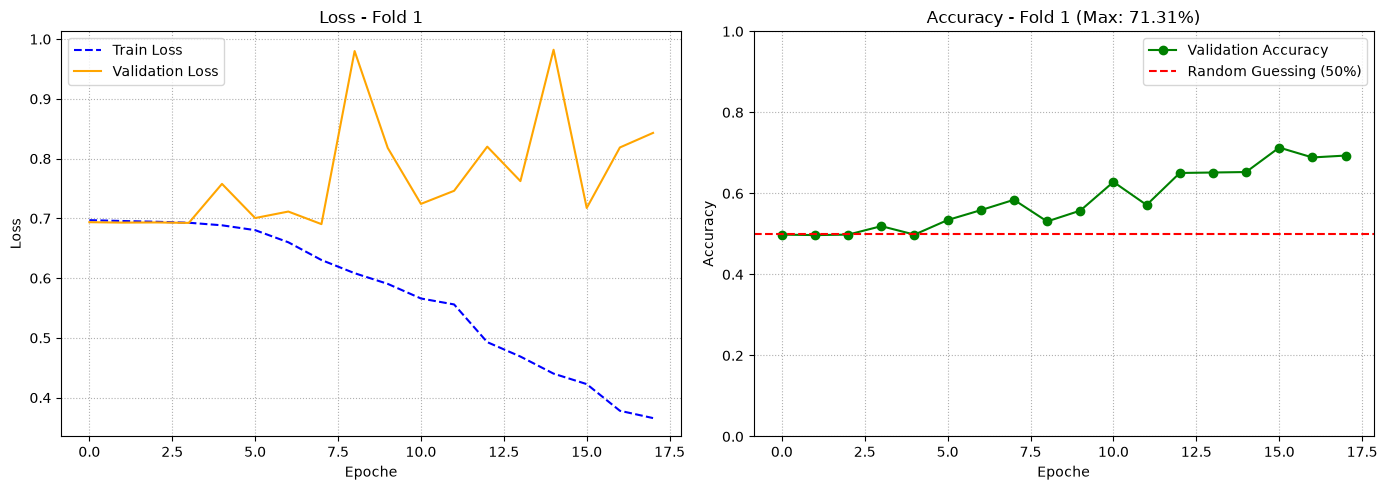


🎉 TRAINING COMPLETATO SU TUTTI I FOLD!
📊 Accuracy media cross-validation: 71.31% (± 0.00%)


In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

import torch

import numpy as np
import torch

def interaug_physionet(timg, label, batch_size=64, device= device):
    """
    Inter-trial Augmentation per PhysioNet (Task Binario: 2 classi, 64 canali, 641 campioni).
    """
    aug_data = []
    aug_label = []
    
    num_classes = 2  # Task binario (Left vs Right)
    samples_per_class = batch_size // num_classes
    num_segments = 8  # Divide i 641 campioni in 8 blocchi temporali
    time_steps = timg.shape[-1]
    seg_size = time_steps // num_segments
    
    for cls4aug in range(num_classes):
        cls_idx = np.where(label == cls4aug)[0]
        if len(cls_idx) == 0:
            continue
            
        tmp_data = timg[cls_idx]
        tmp_aug_data = np.zeros((samples_per_class, timg.shape[1], time_steps))
        
        for ri in range(samples_per_class):
            for rj in range(num_segments):
                rand_idx = np.random.randint(0, tmp_data.shape[0])
                start = rj * seg_size
                end = (rj + 1) * seg_size if rj < num_segments - 1 else time_steps
                tmp_aug_data[ri, :, start:end] = tmp_data[rand_idx, :, start:end]
                
        aug_data.append(tmp_aug_data)
        aug_label.append(np.full((samples_per_class,), cls4aug, dtype=np.int64))
        
    aug_data = np.concatenate(aug_data)
    aug_label = np.concatenate(aug_label)
    
    aug_shuffle = np.random.permutation(len(aug_data))
    aug_data = aug_data[aug_shuffle]
    aug_label = aug_label[aug_shuffle]
    
    aug_data = torch.from_numpy(aug_data).float().to(device)
    aug_label = torch.from_numpy(aug_label).long().to(device)
    
    return aug_data, aug_label

def zscore_per_trial_torch(X, eps=1e-8):
    """
    X shape: (batch_size, n_channels, time_steps) oppure (n_trials, n_channels, time_steps)
    """
    mean = X.mean(dim=-1, keepdim=True)
    std = X.std(dim=-1, keepdim=True, unbiased=False) # unbiased=False per rispecchiare np.std
    
    # Previene divisione per zero in PyTorch
    std = torch.clamp(std, min=eps)
    
    return (X - mean) / std


# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 64        # Ridotto a 32 per stabilizzare i gradienti sui Transformer EEG
EPOCHS = 20            # Leggermente aumentate, ci pensa l'Early Stopping a fermare tutto
LR = 1e-3           # Learning rate leggermente più prudente per il Transformer
WEIGHT_DECAY = 1e-1     # Strong weight decay per regolarizzare contro l'overfitting
ALPHA_NOISE = 0.00      # Intensità del rumore di augmentation
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


       
    # C. APPLICAZIONE DELLA TUA FUNZIONE DI NORMALIZZAZIONE PER-TRIAL
    X_train_norm = zscore_per_trial_torch(X_train_tensor)
    X_val_norm = zscore_per_trial_torch(X_val_tensor)

    print("--- Diagnostica Normalizzazione Training Set ---")
    print(f"Minimo: {X_train_norm.min().item():.4f}")
    print(f"Massimo: {X_train_norm.max().item():.4f}")
    print(f"Media globale: {X_train_norm.mean().item():.4f}")
    print(f"Deviazione standard globale: {X_train_norm.std().item():.4f}")

    # Controllo se ci sono valori anomali, NaN o Inf
    has_nan = torch.isnan(X_train_norm).any().item()
    has_inf = torch.isinf(X_train_norm).any().item()
    print(f"Presenza di NaN? {'⚠️ SÌ' if has_nan else '✅ No'}")
    print(f"Presenza di Inf? {'⚠️ SÌ' if has_inf else '✅ No'}")
    print("-" * 45)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_norm.numpy(), y_train)
    val_dataset = EEGDataset(X_val_norm.numpy(), y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=40,  # Impostato a 40 per coincidere con k=40 della CNN ed evitare mismatch
        nhead=4, num_layers=2, d_ff=160, dropout=0.5, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )
    # H. Trainer personalizzato
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    print("Controllo rapido del batch di training...")
    for inputs, labels in train_loader:
        print(f"Forma batch input: {inputs.shape} (Atteso: [Batch, 64, 641])")
        print(f"Forma batch labels: {labels.shape} (Atteso: [Batch])")
        print(f"Tipo dati labels: {labels.dtype} (Atteso: torch.int64)")
        
        # Test di forward pass per verificare che non ci siano crash di shape
        outputs, _ = model(inputs.to(device))
        print(f"Forma output modello: {outputs.shape} (Atteso: [Batch, 2])")
        break
    print("Diagnostica superata con successo! Avvio le epoche...\n")

    # I. Training e Validazione con Early Stopping integrato
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler,
         max_grad_norm=3.0
    )

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    # Salvataggio del modello migliore assoluto
    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
print(f"\n🎉 TRAINING COMPLETATO SU TUTTI I FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

CODICE CON S&R

In [7]:
import random
import copy 
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

import torch

import numpy as np
import torch

def interaug_physionet(timg, label, batch_size=64, device= device):
    """
    Inter-trial Augmentation per PhysioNet (Task Binario: 2 classi, 64 canali, 641 campioni).
    """
    aug_data = []
    aug_label = []
    
    num_classes = 2  # Task binario (Left vs Right)
    samples_per_class = batch_size // num_classes
    num_segments = 8  # Divide i 641 campioni in 8 blocchi temporali
    time_steps = timg.shape[-1]
    seg_size = time_steps // num_segments
    
    for cls4aug in range(num_classes):
        cls_idx = np.where(label == cls4aug)[0]
        if len(cls_idx) == 0:
            continue
            
        tmp_data = timg[cls_idx]
        tmp_aug_data = np.zeros((samples_per_class, timg.shape[1], time_steps))
        
        for ri in range(samples_per_class):
            for rj in range(num_segments):
                rand_idx = np.random.randint(0, tmp_data.shape[0])
                start = rj * seg_size
                end = (rj + 1) * seg_size if rj < num_segments - 1 else time_steps
                tmp_aug_data[ri, :, start:end] = tmp_data[rand_idx, :, start:end]
                
        aug_data.append(tmp_aug_data)
        aug_label.append(np.full((samples_per_class,), cls4aug, dtype=np.int64))
        
    aug_data = np.concatenate(aug_data)
    aug_label = np.concatenate(aug_label)
    
    aug_shuffle = np.random.permutation(len(aug_data))
    aug_data = aug_data[aug_shuffle]
    aug_label = aug_label[aug_shuffle]
    
    aug_data = torch.from_numpy(aug_data).float().to(device)
    aug_label = torch.from_numpy(aug_label).long().to(device)
    
    return aug_data, aug_label

def zscore_per_trial_torch(X, eps=1e-8):
    """
    X shape: (batch_size, n_channels, time_steps) oppure (n_trials, n_channels, time_steps)
    """
    mean = X.mean(dim=-1, keepdim=True)
    std = X.std(dim=-1, keepdim=True, unbiased=False) # unbiased=False per rispecchiare np.std
    
    # Previene divisione per zero in PyTorch
    std = torch.clamp(std, min=eps)
    
    return (X - mean) / std


# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 128        # Ridotto a 32 per stabilizzare i gradienti sui Transformer EEG
EPOCHS = 20            # Leggermente aumentate, ci pensa l'Early Stopping a fermare tutto
LR = 1e-3           # Learning rate leggermente più prudente per il Transformer
WEIGHT_DECAY = 1e-1     # Strong weight decay per regolarizzare contro l'overfitting
ALPHA_NOISE = 0.00      # Intensità del rumore di augmentation
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


       
    # C. APPLICAZIONE DELLA TUA FUNZIONE DI NORMALIZZAZIONE PER-TRIAL
    X_train_norm = zscore_per_trial_torch(X_train_tensor)
    X_val_norm = zscore_per_trial_torch(X_val_tensor)

    print("--- Diagnostica Normalizzazione Training Set ---")
    print(f"Minimo: {X_train_norm.min().item():.4f}")
    print(f"Massimo: {X_train_norm.max().item():.4f}")
    print(f"Media globale: {X_train_norm.mean().item():.4f}")
    print(f"Deviazione standard globale: {X_train_norm.std().item():.4f}")

    # Controllo se ci sono valori anomali, NaN o Inf
    has_nan = torch.isnan(X_train_norm).any().item()
    has_inf = torch.isinf(X_train_norm).any().item()
    print(f"Presenza di NaN? {'⚠️ SÌ' if has_nan else '✅ No'}")
    print(f"Presenza di Inf? {'⚠️ SÌ' if has_inf else '✅ No'}")
    print("-" * 45)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_norm.numpy(), y_train)
    val_dataset = EEGDataset(X_val_norm.numpy(), y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = EEGConformer(
        num_channels=64, time_steps=641, d_model=40,  # Impostato a 40 per coincidere con k=40 della CNN ed evitare mismatch
        nhead=4, num_layers=2, d_ff=160, dropout=0.5, num_classes=2
    ).to(device)
    
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       # Monitora la discesa della validation loss
        factor=0.5,       # Dimezza il learning rate quando si attiva (lr = lr * 0.5)
        patience=3,       # Se per 3 epoche la val loss non migliora, agisce
        )
    # H. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min',       
        factor=0.5,       
        patience=3,       
    )

    early_stopper = EarlyStopper(patience=10, min_delta=1e-4)

    # Prepariamo i numpy array di training per interaug
    raw_train_data = X_train_norm.numpy()  # shape: (N, 64, 641)
    raw_train_labels = y_train             # shape: (N,)

    train_losses = []
    val_losses = []
    val_accuracies = []
    best_val_acc = 0.0
    best_model_weights = copy.deepcopy(model.state_dict()) if 'copy' in globals() else None

    print("Diagnostica superata con successo! Avvio le epoche con Interaug...\n")

    # ==========================================
    # I. CICLO DELLE EPOCHE CON INTERAUG
    # ==========================================
    for epoch in range(EPOCHS):
        # --- TRAINING ---
        model.train()
        running_loss = 0.0
        num_batches = len(raw_train_data) // BATCH_SIZE

        for _ in range(num_batches):
            optimizer.zero_grad()
            
            # Generazione del batch aumentato al volo con Interaug
            inputs, labels = interaug_physionet(
                raw_train_data, 
                raw_train_labels, 
                batch_size=BATCH_SIZE, 
                device=device
            )

            outputs, _ = model(inputs)
            loss = criterion(outputs, labels)
            
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=3.0)
            optimizer.step()
            
            running_loss += loss.item()

        epoch_loss = running_loss / num_batches

        # --- VALIDAZIONE ---
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for val_inputs, val_labels in val_loader:
                val_inputs = val_inputs.to(device)
                val_labels = val_labels.to(device)

                outputs, _ = model(val_inputs)
                loss = criterion(outputs, val_labels)
                val_loss += loss.item()

                preds = torch.argmax(outputs, dim=1)
                correct += (preds == val_labels).sum().item()
                total += val_labels.size(0)

        eval_loss = val_loss / len(val_loader)
        eval_acc = correct / total

        # Scheduler step
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(eval_loss)
        else:
            scheduler.step()

        train_losses.append(epoch_loss)
        val_losses.append(eval_loss)
        val_accuracies.append(eval_acc)

        # Salvataggio miglior modello del fold
        if eval_acc > best_val_acc:
            best_val_acc = eval_acc
            best_model_weights = copy.deepcopy(model.state_dict())

        print(
            f'Epoch {epoch + 1:02d}/{EPOCHS:02d}: '
            f'train_loss={epoch_loss:.5f}, val_loss={eval_loss:.5f}, val_acc={eval_acc * 100:.2f}%'
        )

        if early_stopper.early_stop(eval_loss):
            print(f"Early stopping all'epoca {epoch+1}")
            break

    # Ricarica i pesi migliori del fold
    model.load_state_dict(best_model_weights)

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break  # rimosso o tenuto a seconda se vuoi testare solo il primo fold

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- INIZIO TRAINING & VALIDAZIONE - FOLD 1/5 ---
--- Diagnostica Normalizzazione Training Set ---
Minimo: -12.2701
Massimo: 10.9622
Media globale: -0.0000
Deviazione standard globale: 1.0000
Presenza di NaN? ✅ No
Presenza di Inf? ✅ No
---------------------------------------------
Diagnostica superata con successo! Avvio le epoche con Interaug...

Epoch 01/20: train_loss=0.69823, val_loss=0.69261, val_acc=52.10%
Epoch 02/20: train_loss=0.69457, val_loss=0.69239, val_acc=53.58%
Epoch 03/20: train_loss=0.69192, val_loss=0.69121, val_acc=55.19%
Epoch 04/20: train_loss=0.69184, val_loss=0.69488, val_acc=51.85%
Epoch 05/20: train_loss=0.68413, val_loss=0.69531, val_acc=56.91%
Epoch 06/20: train_loss=0.65910, val_loss=0.72715, val_acc=56.54%
Epoch 07/20: train_loss=0.63295, val_loss=0.77380, val_acc=58.64%
Epoch 08/20: train_loss=0.61566, val_loss=0.71279, val_acc=62.47%
Epoch 09/20: train_loss=0.56753, val_loss=0.81405, val_acc=60.37%
Epoch 10/20: t

KeyboardInterrupt: 